# 🐟 Fish — AquaCare AI DO Training

This notebook is **only for 🐟 Fish Dissolved Oxygen (DO) prediction**.

It will:
- load the 🐟 Fish DO dataset
- inspect and clean the data
- select useful water-quality/environment features
- train a Random Forest regression model
- evaluate MAE, RMSE and R²
- plot Actual vs Predicted DO
- plot feature importance
- save the trained model as `models/fish_do_model.pkl`

**No fake data and no fake predictions are created.**


In [ ]:
%pip install pandas numpy scikit-learn matplotlib joblib


## 1. Project path and dataset search

Project folder:

`C:\Users\NANDINI\Desktop\AQUA CARE`


In [3]:
from pathlib import Path
import pandas as pd

# =========================================================
# FISH DO DATASET
# =========================================================

DATASET_PATH = Path(
    r"C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\fish_DO.csv"
)

# =========================================================
# PROJECT FOLDER
# =========================================================

PROJECT_DIR = DATASET_PATH.parent

# Models folder
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# =========================================================
# CHECK DATASET
# =========================================================

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"❌ Fish DO dataset not found:\n{DATASET_PATH}"
    )

print("✅ Fish DO dataset found")
print("Dataset:", DATASET_PATH)

print("\n✅ Project folder:")
print(PROJECT_DIR)

print("\n✅ Models folder:")
print(MODELS_DIR)

# =========================================================
# LOAD DATA
# =========================================================

df = pd.read_csv(DATASET_PATH)

print("\nDataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

✅ Fish DO dataset found
Dataset: C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\fish_DO.csv

✅ Project folder:
C:\Users\NANDINI\Desktop\AquaCare_Complete\fish

✅ Models folder:
C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\models

Dataset Shape: (7200, 15)

Columns:
['timestamp', 'pond_id', 'species', 'water_temp_C', 'pH', 'salinity_ppt', 'DO_mg_L', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'aerator_on', 'feed_kg', 'rainfall_mm', 'DO_status', 'mortality_risk']


,timestamp,pond_id,species,water_temp_C,pH,salinity_ppt,DO_mg_L,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,aerator_on,feed_kg,rainfall_mm,DO_status,mortality_risk
0,2026-08-01 00:00:00,F1,Rohu (L. rohita),26.13,7.36,0.31,4.07,0.079,0.062,30.8,1,0.0,0.0,Low,Medium
1,2026-08-01 01:00:00,F1,Rohu (L. rohita),25.28,7.26,0.51,3.50,0.061,0.055,30.5,1,0.0,0.0,Low,Medium
2,2026-08-01 02:00:00,F1,Rohu (L. rohita),25.49,7.14,0.76,4.60,0.050,0.058,28.1,1,0.0,0.0,Low,Low
3,2026-08-01 03:00:00,F1,Rohu (L. rohita),25.43,7.27,0.60,3.27,0.112,0.010,29.6,1,0.0,0.0,Low,Medium
4,2026-08-01 04:00:00,F1,Rohu (L. rohita),25.24,7.15,0.48,3.09,0.065,0.055,22.4,1,0.0,0.0,Low,Medium


## 2. Load and inspect the dataset

In [2]:
df = pd.read_csv(r"C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\fish_DO.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(list(df.columns))

display(df.head())


Shape: (7200, 15)

Columns:
['timestamp', 'pond_id', 'species', 'water_temp_C', 'pH', 'salinity_ppt', 'DO_mg_L', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'aerator_on', 'feed_kg', 'rainfall_mm', 'DO_status', 'mortality_risk']


,timestamp,pond_id,species,water_temp_C,pH,salinity_ppt,DO_mg_L,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,aerator_on,feed_kg,rainfall_mm,DO_status,mortality_risk
0,2026-08-01 00:00:00,F1,Rohu (L. rohita),26.13,7.36,0.31,4.07,0.079,0.062,30.8,1,0.0,0.0,Low,Medium
1,2026-08-01 01:00:00,F1,Rohu (L. rohita),25.28,7.26,0.51,3.50,0.061,0.055,30.5,1,0.0,0.0,Low,Medium
2,2026-08-01 02:00:00,F1,Rohu (L. rohita),25.49,7.14,0.76,4.60,0.050,0.058,28.1,1,0.0,0.0,Low,Low
3,2026-08-01 03:00:00,F1,Rohu (L. rohita),25.43,7.27,0.60,3.27,0.112,0.010,29.6,1,0.0,0.0,Low,Medium
4,2026-08-01 04:00:00,F1,Rohu (L. rohita),25.24,7.15,0.48,3.09,0.065,0.055,22.4,1,0.0,0.0,Low,Medium


## 3. Detect DO target and select useful features

Supported target names:
- `DO_mg_L`
- `dissolved_oxygen_mg_l`
- `dissolved_oxygen`
- `DO`

Useful available inputs may include temperature, pH, salinity, ammonia, nitrite, turbidity, aerator, feed and rainfall.


In [4]:
def normalize_name(value):
    s = str(value).strip().lower()
    for ch in [" ", "-", "/", "\\", "(", ")", "[", "]", "{", "}", "."]:
        s = s.replace(ch, "_")
    while "__" in s:
        s = s.replace("__", "_")
    return s.strip("_")

name_map = {normalize_name(c): c for c in df.columns}

target_candidates = [
    "do_mg_l",
    "dissolved_oxygen_mg_l",
    "dissolved_oxygen",
    "do"
]

target_col = None

for candidate in target_candidates:
    if candidate in name_map:
        target_col = name_map[candidate]
        break

if target_col is None:
    for normalized, original in name_map.items():
        if "oxygen" in normalized and ("mg" in normalized or normalized == "dissolved_oxygen"):
            target_col = original
            break

if target_col is None:
    raise ValueError(
        "DO target column was not found. Expected DO_mg_L or dissolved_oxygen_mg_l."
    )

aliases = {
    "water_temp": ["water_temp_c", "water_temperature_c", "temperature_c", "temperature"],
    "ph": ["ph"],
    "salinity": ["salinity_ppt", "salinity"],
    "ammonia": ["ammonia_mg_l", "ammonia"],
    "nitrite": ["nitrite_mg_l", "nitrite"],
    "turbidity": ["turbidity_ntu", "turbidity"],
    "feed": ["feed_kg", "feeding_rate_kg", "feed_amount_kg", "feeding_rate"],
    "rainfall": ["rainfall_mm", "rainfall"],
    "aerator": ["aerator_on", "aerator_status", "aerator"],
    "stocking_density": ["stocking_density"],
    "pond_area": ["pond_area_acres", "pond_area"],
    "average_weight": ["prawn_average_weight_g", "average_weight_g"],
    "length": ["prawn_length_cm", "length_cm"],
}

feature_cols = []

for alias_list in aliases.values():
    for alias in alias_list:
        if alias in name_map and name_map[alias] != target_col:
            feature_cols.append(name_map[alias])
            break

for normalized, original in name_map.items():
    if normalized in {"species", "fish_species", "prawn_species", "species_name"}:
        if original != target_col:
            feature_cols.append(original)

feature_cols = list(dict.fromkeys(feature_cols))

if not feature_cols:
    raise ValueError("No suitable input features were found in this dataset.")

print("Target:", target_col)
print("Features:", feature_cols)


Target: DO_mg_L
Features: ['water_temp_C', 'pH', 'salinity_ppt', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'feed_kg', 'rainfall_mm', 'aerator_on', 'species']


## 4. Clean data

In [5]:
work = df[feature_cols + [target_col]].copy()

work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
work = work.dropna(subset=[target_col])

print("Rows after cleaning:", len(work))
display(work.isna().sum().to_frame("missing"))


Rows after cleaning: 7200


,missing
water_temp_C,0
pH,0
salinity_ppt,0
ammonia_mg_L,0
nitrite_mg_L,0
turbidity_NTU,0
feed_kg,0
rainfall_mm,0
aerator_on,0
species,0


## 5. Train the Random Forest DO model

In [14]:
import numpy as np
import joblib

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================================================
# FISH - GRADIENT BOOSTING
# =========================================================

fish_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

# IMPORTANT:
# preprocessor already has OneHotEncoder for Species
fish_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", fish_model)
])

# Train
fish_pipeline.fit(X_train, y_train)

# Predict
fish_pred = fish_pipeline.predict(X_test)

# Metrics
fish_mae = mean_absolute_error(y_test, fish_pred)

fish_rmse = np.sqrt(
    mean_squared_error(y_test, fish_pred)
)

fish_r2 = r2_score(
    y_test, fish_pred
)

print("====================================")
print("🐟 FISH DO - GRADIENT BOOSTING")
print("====================================")

print("MAE       :", round(fish_mae, 4), "mg/L")
print("RMSE      :", round(fish_rmse, 4), "mg/L")
print("R²        :", round(fish_r2, 4))
print("R² Score %:", round(fish_r2 * 100, 2), "%")

🐟 FISH DO - GRADIENT BOOSTING
MAE       : 0.4257 mg/L
RMSE      : 0.556 mg/L
R²        : 0.7241
R² Score %: 72.41 %


## 6. Model performance

In [15]:
from pathlib import Path

model_dir = Path(
    r"C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\models"
)

model_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_path = model_dir / "fish_do_best_model.pkl"

joblib.dump(
    fish_pipeline,
    model_path
)

print("✅ Fish best model saved:")
print(model_path)

✅ Fish best model saved:
C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\models\fish_do_best_model.pkl


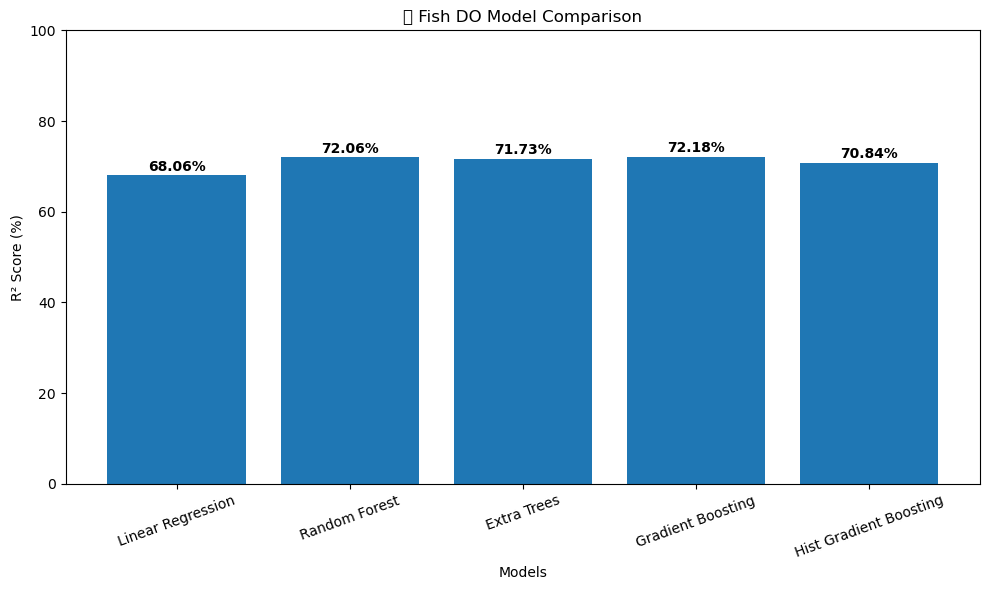

In [26]:
import matplotlib.pyplot as plt

# Fish DO model results
models = [
    "Linear Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "Hist Gradient Boosting"
]

r2_scores = [
    68.06,
    72.06,
    71.73,
    72.18,
    70.84
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, r2_scores)

plt.xlabel("Models")
plt.ylabel("R² Score (%)")
plt.title("🐟 Fish DO Model Comparison")

plt.ylim(0, 100)
plt.xticks(rotation=20)

for bar, value in zip(bars, r2_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## 7. Actual vs Predicted DO

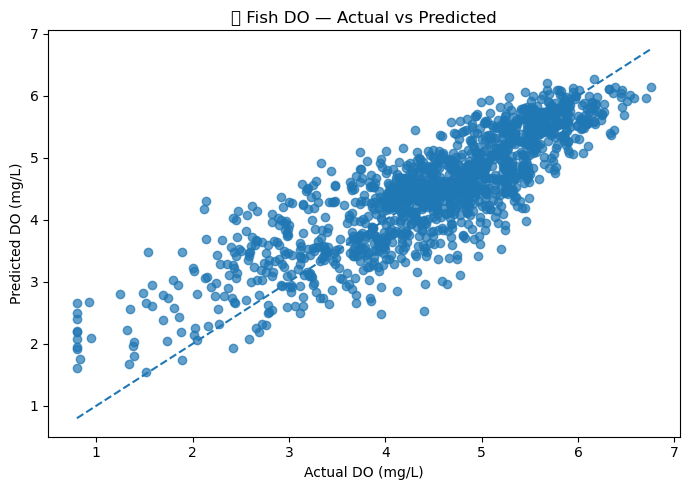

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred, alpha=0.7)

low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual DO (mg/L)")
plt.ylabel("Predicted DO (mg/L)")
plt.title("🐟 Fish DO — Actual vs Predicted")
plt.tight_layout()
plt.show()


## 8. Feature importance

,Feature,Importance
1,pH,0.236560
3,ammonia_mg_L,0.194507
0,water_temp_C,0.188265
5,turbidity_NTU,0.105438
8,aerator_on,0.101618
4,nitrite_mg_L,0.049506
2,salinity_ppt,0.044911
7,rainfall_mm,0.020256
6,feed_kg,0.018080
13,species_Magur Catfish (C. batrachus),0.005931


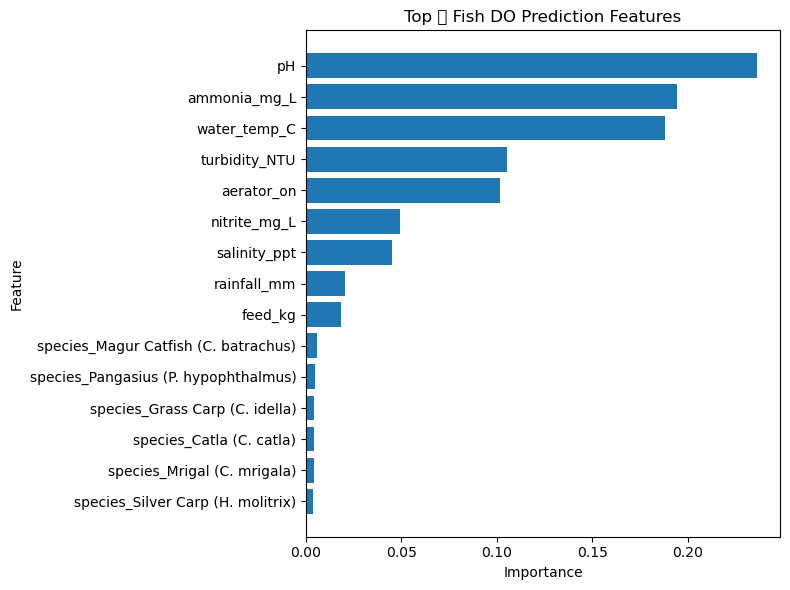

In [19]:
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pipeline.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importance})
    .sort_values("Importance", ascending=False)
)

display(importance_df.head(15))

top = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(top["Feature"], top["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 🐟 Fish DO Prediction Features")
plt.tight_layout()
plt.show()


## 9. Save the trained model

In [20]:
model_path = MODELS_DIR / "fish_do_model.pkl"
metadata_path = MODELS_DIR / "fish_do_metadata.json"

joblib.dump(pipeline, model_path)

metadata = {
    "species": "fish",
    "dataset": str(DATASET_PATH),
    "target_column": target_col,
    "feature_columns": feature_cols,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "MAE": float(mae),
    "RMSE": float(rmse),
    "R2": float(r2)
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("✅ Model saved to:", model_path)
print("✅ Metadata saved to:", metadata_path)


✅ Model saved to: C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\models\fish_do_model.pkl
✅ Metadata saved to: C:\Users\NANDINI\Desktop\AquaCare_Complete\fish\models\fish_do_metadata.json


## 10. Test one real row from the dataset

The test input below is taken from the actual test set. No fabricated sample is created.

In [21]:
sample = X_test.iloc[[0]].copy()
sample_prediction = float(pipeline.predict(sample)[0])

print("Actual input row:")
display(sample)

print("Predicted DO:", round(sample_prediction, 3), "mg/L")


Actual input row:


,water_temp_C,pH,salinity_ppt,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,feed_kg,rainfall_mm,aerator_on,species
3098,25.88,7.05,0.25,0.12,0.061,26.7,0.0,0.0,1,Grass Carp (C. idella)


Predicted DO: 3.823 mg/L


## 11. DO screening status

These are the current AquaCare project screening bands and should remain configurable for the target species/pond.

In [23]:
DO_THRESHOLDS = {
    "optimal_min": 5.0,
    "moderate_min": 3.0,
    "low_min": 2.0,
}

def classify_do(value):
    if value >= DO_THRESHOLDS["optimal_min"]:
        return "Optimal"
    elif value >= DO_THRESHOLDS["moderate_min"]:
        return "Moderate"
    elif value >= DO_THRESHOLDS["low_min"]:
        return "Low"
    return "Critical"

print("Predicted status:", classify_do(sample_prediction))


Predicted status: Moderate


# ✅ 🐟 Fish DO training complete

The trained model is saved inside your project:

```text
AQUA CARE/
└── models/
    ├── fish_do_model.pkl
    └── fish_do_metadata.json
```

This `.pkl` model can be connected to the Flask AquaCare AI application.
